# 🔍 Anomaly Detection & Risk Scoring — hands-on

**Birlasoft FORGE FDE Academy · Sprint 2 · Days 26–28 · DecisionStream AI**

---

## The case we are working on

**Meridian General Insurance** settles about 4,000 motor claims a month. Sprint 1
gave them a pipeline that reads a claim pack and produces a decision profile. It
works well.

Then Finance notices something: over six months, **38 claims were paid into only
4 bank accounts.**

Every single claim was valid. Real accident, real garage, real invoice. No
individual claim looked wrong — and that is exactly the difficulty. The pattern
is only visible *across* cases.

Sprint 1 looked at one document. Sprint 2 looks at the relationship between many
cases, over time.

---

## What is real in this notebook

| Part | Real or simulated |
|---|---|
| The case data | **Generated here** — with a realistic fraud rate, not a convenient one |
| Rules engine | **Real** — you write and run it |
| Model training | **Real** — scikit-learn, actual fitting |
| AUC, PR-AUC, precision, recall | **Real** — measured on a held-out set |
| Reviews-per-day arithmetic | **Real** — from your own threshold |
| Registering the model to Azure ML | **Real, and optional** — needs a workspace |

Everything that teaches the concept runs without any Azure account. The Azure
section at the end is where you connect it to a real workspace, and **Appendix A
walks you through creating one.**

---

## A note on the names in your syllabus

Your syllabus says *"Azure Machine Learning (Fraud Detection model)"* and then
uses words like **event type, entity, detector, Online Fraud Insights**.

Those words come from a **managed fraud-scoring product**, not from Azure
Machine Learning. If you search the Azure ML documentation for "detector" you
will find nothing, and you will think you have misunderstood. You have not.

| Vocabulary | Belongs to |
|---|---|
| event type, entity, variable, detector, Online Fraud Insights | a managed fraud product — you configure, it hosts and scores |
| workspace, dataset, experiment, run, registered model, endpoint | **Azure Machine Learning** — you bring the model |

**Check with your engagement lead which service is actually licensed** before
configuring anything on a client site.

The good news: the *method* is identical either way. Define the event, choose
the variables, write rules for what you know, train a model for what you do not,
measure it honestly, and route the result to a human. Only the console changes.

This notebook uses **Azure Machine Learning**, because that is what the syllabus
names.

## 0 · Install and import

In [1]:
%pip install -q scikit-learn pandas numpy matplotlib azure-ai-ml azure-identity

import os, re, json, math, getpass, warnings, itertools
from dataclasses import dataclass, field
from datetime import datetime, timedelta, timezone

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve,
                             precision_score, recall_score, confusion_matrix)

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
print("ready")

Note: you may need to restart the kernel to use updated packages.
ready


---

# Day 26 · Configure the detector

## What we are doing today, and why

**The intent is not to catch fraud.** It is to make the client say out loud what
they already suspect, and turn that into something a machine checks on every
single case.

The knowledge is already in the room. Ask a senior claims handler at Meridian
what a suspicious claim looks like and they will tell you in five minutes.
Nobody has ever written it down.

**As an FDE you are not inventing risk logic. You are extracting it from people
who have it, and encoding it so it runs on all 4,000 cases — not just the ones a
good handler happens to see.**

---

## Exercise 1 · Define the event and its variables

Four words, in plain language:

| Word | Plain meaning | For Meridian |
|---|---|---|
| **Event type** | The thing that happens and needs checking | `case_application` — a claim arriving |
| **Entity** | Who or what the event is about | claimant, policy, garage, bank account |
| **Variable** | One fact about the event that might matter | `days_since_incident` |
| **Detector** | The thing that reads the variables and produces an opinion | rules today, rules + model from Day 27 |

> The **event** is what happened. The **entities** are who it involved. The
> **variables** are the facts. The **detector** is the opinion.

In [2]:
# The eight variables, each with the reason it earns its place.
VARIABLES = {
  "declared_income":          ("number",  "Income far above the profile for that policy band"),
  "estimate_vs_limit_pct":    ("number",  "Claims sitting just under the policy limit, repeatedly"),
  "days_since_incident":      ("number",  "Very late reporting — or suspiciously immediate"),
  "application_velocity_30d": ("number",  "How many claims from this claimant in 30 days"),
  "device_fingerprint_reuse": ("number",  "One device submitting for many unrelated claimants"),
  "bank_account_reuse_count": ("number",  "THE MERIDIAN PATTERN — one account, many claimants"),
  "garage_claim_share_90d":   ("number",  "One garage in an unusual share of claims"),
  "policy_age_days":          ("number",  "A claim very soon after the policy started"),
}

EVENT_TYPE = "case_application"
ENTITIES   = ["claimant", "policy", "garage", "bank_account"]

print(f"event type : {EVENT_TYPE}")
print(f"entities   : {', '.join(ENTITIES)}\n")
print(f"{'variable':<28}{'type':<10}why it is on the list")
print("-" * 100)
for name, (typ, why) in VARIABLES.items():
    print(f"{name:<28}{typ:<10}{why}")

print("""
TWO OF THESE ARE NOT REALLY ABOUT ONE CLAIM

bank_account_reuse_count and garage_claim_share_90d describe this claim's
RELATIONSHIP to other claims. They are the ones that would have caught
Meridian — and they are also the ones that need history, which means somebody
has to build and maintain that lookup. That is real work; do not under-scope it.
""")

event type : case_application
entities   : claimant, policy, garage, bank_account

variable                    type      why it is on the list
----------------------------------------------------------------------------------------------------
declared_income             number    Income far above the profile for that policy band
estimate_vs_limit_pct       number    Claims sitting just under the policy limit, repeatedly
days_since_incident         number    Very late reporting — or suspiciously immediate
application_velocity_30d    number    How many claims from this claimant in 30 days
device_fingerprint_reuse    number    One device submitting for many unrelated claimants
bank_account_reuse_count    number    THE MERIDIAN PATTERN — one account, many claimants
garage_claim_share_90d      number    One garage in an unusual share of claims
policy_age_days             number    A claim very soon after the policy started

TWO OF THESE ARE NOT REALLY ABOUT ONE CLAIM

bank_account_reuse_co

### The two questions to ask about every variable

Before a variable goes on the list, it has to survive both of these.

In [3]:
# Fill this in for every variable. It takes ten minutes and it is the artefact
# a reviewer will ask for.
CHECKS = {
  # variable                   available at scoring time?         proxy risk?
  "declared_income":          ("yes — on the application form",   "low"),
  "estimate_vs_limit_pct":    ("yes — extraction + policy data",  "low"),
  "days_since_incident":      ("yes — two dates on the form",     "low"),
  "application_velocity_30d": ("needs a live lookup",             "low"),
  "device_fingerprint_reuse": ("yes — if the portal captures it", "low"),
  "bank_account_reuse_count": ("needs a live lookup",             "low"),
  "garage_claim_share_90d":   ("needs a live lookup",             "CHECK — see below"),
  "policy_age_days":          ("yes — policy record",             "low"),
}

print(f"{'variable':<28}{'available at scoring time':<36}proxy risk")
print("-" * 92)
for v, (avail, proxy) in CHECKS.items():
    mark = "  !!" if proxy != "low" else "    "
    print(f"{v:<28}{avail:<36}{proxy}{mark}")

print("""
LEAKAGE — the first question

A variable you only know AFTER the claim is settled cannot score it at
submission. Three of the eight need a live lookup. If that lookup runs as an
overnight batch, your scoring is a day late and the variable is useless.

FAIRNESS — the second question

None of the eight is a protected characteristic, and you should be able to say
so. But look at garage_claim_share_90d: in a small town, one garage can
correlate strongly with one community. A variable can be perfectly reasonable
in general and act as a proxy in a specific geography.

The model does not know these are sensitive. It will use them happily, and it
is very hard to detect afterwards.

ACTION: record who reviewed this table and on what date. In two years somebody
will ask why garage share is in there.
""")

variable                    available at scoring time           proxy risk
--------------------------------------------------------------------------------------------
declared_income             yes — on the application form       low    
estimate_vs_limit_pct       yes — extraction + policy data      low    
days_since_incident         yes — two dates on the form         low    
application_velocity_30d    needs a live lookup                 low    
device_fingerprint_reuse    yes — if the portal captures it     low    
bank_account_reuse_count    needs a live lookup                 low    
garage_claim_share_90d      needs a live lookup                 CHECK — see below  !!
policy_age_days             yes — policy record                 low    

LEAKAGE — the first question

A variable you only know AFTER the claim is settled cannot score it at
submission. Three of the eight need a live lookup. If that lookup runs as an
overnight batch, your scoring is a day late and the variable is

## Exercise 2 · Generate the case data

We need cases to work with. This generator makes **realistic** data, which
matters more than it sounds.

> Your syllabus suggests 2,000 cases with 150 fraud — a **7.5%** fraud rate.
> Real motor claims fraud is well under 2%, and confirmed fraud lower still.
>
> A 7.5% training set makes the problem look far easier than production will be.
> We will generate at a realistic rate and you will see the difference.

In [4]:
RNG = np.random.default_rng(42)
N_CASES = 4000
FRAUD_RATE = 0.018          # ~1.8% — realistic. Change to 0.075 later and compare.

def clip(v, lo, hi):
    """rng.normal() returns a plain float, which has no .clip(). Easy to miss."""
    return float(min(max(v, lo), hi))

def generate_cases(n=N_CASES, fraud_rate=FRAUD_RATE, rng=RNG):
    n_fraud = int(n * fraud_rate)
    n_clean = n - n_fraud
    rows = []

    # ---- legitimate claims ----
    for i in range(n_clean):
        rows.append({
          "case_id": f"CLM-2026-{10000+i}",
          "declared_income":          clip(rng.normal(38000, 12000), 12000, 200000),
          "estimate_vs_limit_pct":    clip(rng.beta(2, 5), 0.02, 0.99),
          "days_since_incident":      int(clip(rng.gamma(2.2, 3.2), 0, 90)),
          "application_velocity_30d": int(rng.poisson(0.15)),
          "device_fingerprint_reuse": int(rng.poisson(0.3)),
          "bank_account_reuse_count": int(rng.poisson(0.2)),
          "garage_claim_share_90d":   clip(rng.beta(1.5, 30), 0, 1),
          "policy_age_days":          int(clip(rng.gamma(3, 260), 1, 4000)),
          "is_fraud": 0,
        })

    # ---- fraudulent claims ----
    #
    # THE HARD PART OF MAKING GOOD SYNTHETIC DATA is resisting the urge to make
    # fraud obvious. If the fraud distributions barely overlap the legitimate
    # ones, your model scores an AUC of 1.0, every trade-off disappears, and the
    # exercise teaches nothing. Real fraud LOOKS LIKE ordinary business.
    #
    # So: the shifts below are deliberately small, and a share of fraud cases
    # are generated as completely ordinary. Those are the ones that get missed,
    # and they should be - no model can find a signal that is not there.
    UNLEARNABLE = 0.20          # fraud that looks exactly like a normal claim

    for i in range(n_fraud):
        ordinary = rng.random() < UNLEARNABLE
        pattern = ("invisible" if ordinary
                   else rng.choice(["ring", "opportunist", "staged"], p=[0.45, 0.35, 0.20]))
        base = {
          "case_id": f"CLM-2026-{90000+i}",
          "declared_income":          clip(rng.normal(38000, 12000), 12000, 200000),
          "device_fingerprint_reuse": int(rng.poisson(0.35)),
          "is_fraud": 1,
        }
        if ordinary:
            base.update({
              "estimate_vs_limit_pct":    clip(rng.beta(2, 5), 0.02, 0.99),
              "days_since_incident":      int(clip(rng.gamma(2.2, 3.2), 0, 90)),
              "application_velocity_30d": int(rng.poisson(0.15)),
              "bank_account_reuse_count": int(rng.poisson(0.2)),
              "garage_claim_share_90d":   clip(rng.beta(1.5, 30), 0, 1),
              "policy_age_days":          int(clip(rng.gamma(3, 260), 1, 4000)),
            })
        elif pattern == "ring":          # the Meridian pattern - still subtle
            base.update({
              "estimate_vs_limit_pct":    clip(rng.beta(5, 2.6), 0.02, 0.99),
              "days_since_incident":      int(clip(rng.gamma(3.0, 4.0), 0, 90)),
              "application_velocity_30d": int(rng.poisson(0.3)),
              "bank_account_reuse_count": int(rng.poisson(2.4)),
              "garage_claim_share_90d":   clip(rng.beta(2.8, 20), 0, 1),
              "policy_age_days":          int(clip(rng.gamma(3, 260), 1, 4000)),
            })
        elif pattern == "opportunist":
            base.update({
              "estimate_vs_limit_pct":    clip(rng.beta(3.4, 3.2), 0.02, 0.99),
              "days_since_incident":      int(clip(rng.gamma(3.4, 4.2), 0, 90)),
              "application_velocity_30d": int(rng.poisson(0.2)),
              "bank_account_reuse_count": int(rng.poisson(0.35)),
              "garage_claim_share_90d":   clip(rng.beta(1.6, 27), 0, 1),
              "policy_age_days":          int(clip(rng.gamma(3, 260), 1, 4000)),
            })
        else:                            # staged - newer policy, but overlapping
            base.update({
              "estimate_vs_limit_pct":    clip(rng.beta(2.6, 4.0), 0.02, 0.99),
              "days_since_incident":      int(clip(rng.gamma(2.0, 3.0), 0, 90)),
              "application_velocity_30d": int(rng.poisson(0.45)),
              "bank_account_reuse_count": int(rng.poisson(0.6)),
              "garage_claim_share_90d":   clip(rng.beta(1.8, 26), 0, 1),
              "policy_age_days":          int(clip(rng.gamma(1.4, 190), 1, 4000)),
            })
        base["fraud_pattern"] = pattern
        rows.append(base)

    df = pd.DataFrame(rows).sample(frac=1, random_state=7).reset_index(drop=True)
    df["fraud_pattern"] = df.get("fraud_pattern", pd.Series(dtype=object)).fillna("-")
    return df

cases = generate_cases()
print(f"generated {len(cases):,} cases")
print(f"fraud     {cases.is_fraud.sum():,}  ({cases.is_fraud.mean():.2%})")
print(f"clean     {(1-cases.is_fraud).sum():,}\n")
print("fraud patterns:")
print(cases[cases.is_fraud == 1].fraud_pattern.value_counts().to_string())
print(f"""
NOTICE: {cases.is_fraud.sum()} fraud cases in {len(cases):,}. That is the
number you have to learn from, and it is small. Every metric you compute later
rests on it — treat decimal places with suspicion.

Also notice there are THREE fraud patterns, not one. Real fraud is not a single
shape, and a model that learns only the loudest pattern will miss the others.
""")
cases.head(5)

generated 4,000 cases
fraud     72  (1.80%)
clean     3,928

fraud patterns:
fraud_pattern
ring           27
opportunist    19
staged         14
invisible      12

NOTICE: 72 fraud cases in 4,000. That is the
number you have to learn from, and it is small. Every metric you compute later
rests on it — treat decimal places with suspicion.

Also notice there are THREE fraud patterns, not one. Real fraud is not a single
shape, and a model that learns only the loudest pattern will miss the others.



,case_id,declared_income,estimate_vs_limit_pct,days_since_incident,application_velocity_30d,device_fingerprint_reuse,bank_account_reuse_count,garage_claim_share_90d,policy_age_days,is_fraud,fraud_pattern
0,CLM-2026-12060,23550.394590,0.170760,15,0,2,0,0.015537,1277,0,-
1,CLM-2026-10933,40625.919548,0.211875,6,1,0,0,0.061311,142,0,-
2,CLM-2026-10378,45469.292561,0.192929,2,0,0,0,0.050999,286,0,-
3,CLM-2026-12754,51709.300490,0.129607,1,0,0,0,0.036864,379,0,-
4,CLM-2026-10596,56329.428152,0.167700,7,0,0,0,0.097692,437,0,-


## Exercise 3 · Write the rules

Start with what a good handler already knows. Each rule should be **one sentence
somebody actually said**, translated.

Rules never go away, even after you have a model:

> A **rule** is an obligation you have accepted.
> A **model** is a probability you have estimated.
>
> If the client says *"any claim over £50,000 must always be reviewed"*, that is
> a rule. A model might score it low and let it through.

In [5]:
@dataclass
class Rule:
    name: str
    weight: int
    test: object          # a function of the case row
    said_by: str          # the sentence a human actually said

RULES = [
  Rule("late_and_near_limit", 30,
       lambda c: c["days_since_incident"] > 21 and c["estimate_vs_limit_pct"] > 0.90,
       "I get suspicious when a claim comes in late AND it is close to the limit."),
  Rule("repeated_bank_account", 45,
       lambda c: c["bank_account_reuse_count"] >= 3,
       "If the same account keeps showing up, I want to look at all of them together."),
  Rule("new_policy_high_value", 35,
       lambda c: c["policy_age_days"] < 30 and c["estimate_vs_limit_pct"] > 0.80,
       "A big claim in the first month of a policy is worth a second look."),
  Rule("garage_concentration", 25,
       lambda c: c["garage_claim_share_90d"] > 0.20,
       "One garage doing a fifth of our claims in an area is not normal."),
  Rule("claim_velocity", 20,
       lambda c: c["application_velocity_30d"] >= 3,
       "Three claims in a month from one claimant needs explaining."),
]

def apply_rules(case):
    """Returns (score, [names of rules that fired])."""
    fired, score = [], 0
    for r in RULES:
        try:
            if r.test(case):
                fired.append(r.name); score += r.weight
        except (KeyError, TypeError):
            pass
    return min(score, 100), fired

print("the rules, and the sentence each one came from\n")
for r in RULES:
    print(f"  {r.name:<26} +{r.weight}")
    print(f"      \u201C{r.said_by}\u201D\n")

# Test on 5 synthetic cases — INCLUDING a clean one.
tests = [
  ("clean claim",            dict(days_since_incident=4,  estimate_vs_limit_pct=0.31,
                                  bank_account_reuse_count=0, policy_age_days=900,
                                  garage_claim_share_90d=0.02, application_velocity_30d=0)),
  ("late and near limit",    dict(days_since_incident=26, estimate_vs_limit_pct=0.94,
                                  bank_account_reuse_count=0, policy_age_days=800,
                                  garage_claim_share_90d=0.03, application_velocity_30d=0)),
  ("repeated bank account",  dict(days_since_incident=9,  estimate_vs_limit_pct=0.60,
                                  bank_account_reuse_count=7, policy_age_days=700,
                                  garage_claim_share_90d=0.05, application_velocity_30d=1)),
  ("brand new policy",       dict(days_since_incident=11, estimate_vs_limit_pct=0.88,
                                  bank_account_reuse_count=1, policy_age_days=18,
                                  garage_claim_share_90d=0.04, application_velocity_30d=0)),
  ("the Meridian shape",     dict(days_since_incident=24, estimate_vs_limit_pct=0.92,
                                  bank_account_reuse_count=9, policy_age_days=210,
                                  garage_claim_share_90d=0.28, application_velocity_30d=1)),
]

print(f"{'test case':<24}{'score':>7}   rules that fired")
print("-" * 92)
for label, c in tests:
    sc, fired = apply_rules(c)
    print(f"{label:<24}{sc:>7}   {', '.join(fired) if fired else '(none)'}")

print("""
THE CLEAN CASE IS THE IMPORTANT TEST

If your clean case scores anything above zero, your thresholds are wrong and it
is much better to find that out now. A detector that flags ordinary claims will
be switched off within a fortnight, and nobody will tell you.
""")

the rules, and the sentence each one came from

  late_and_near_limit        +30
      “I get suspicious when a claim comes in late AND it is close to the limit.”

  repeated_bank_account      +45
      “If the same account keeps showing up, I want to look at all of them together.”

  new_policy_high_value      +35
      “A big claim in the first month of a policy is worth a second look.”

  garage_concentration       +25
      “One garage doing a fifth of our claims in an area is not normal.”

  claim_velocity             +20
      “Three claims in a month from one claimant needs explaining.”

test case                 score   rules that fired
--------------------------------------------------------------------------------------------
clean claim                   0   (none)
late and near limit          30   late_and_near_limit
repeated bank account        45   repeated_bank_account
brand new policy             35   new_policy_high_value
the Meridian shape          100   late_and_near

---

# Day 27 · Train the model

## What we are doing today, and why

Rules catch what somebody already knows. A model finds **combinations** nobody
thought to describe — and that is where the Meridian pattern was hiding.

| Rules are good at | A model is good at |
|---|---|
| Known patterns | Combinations — this is fine, and that is fine, but together they are unusual |
| Hard obligations | Weighting signals by how much they actually predicted |
| Explaining themselves in one sentence | Noticing weak patterns across thousands of cases |
| Being changed in five minutes | Finding what nobody described |

**You are not replacing the rules.** You run both: the rules keep the promises,
the model widens the net.

## Exercise 4 · Score everything with rules alone, first

In [6]:
# Baseline: what do the rules alone achieve?
rule_scores, rule_fired = [], []
for _, c in cases.iterrows():
    s, f = apply_rules(c)
    rule_scores.append(s); rule_fired.append(f)
cases["rule_score"] = rule_scores
cases["rules_fired"] = ["|".join(f) for f in rule_fired]

RULE_THRESHOLD = 30
flagged = cases.rule_score >= RULE_THRESHOLD
tp = int((flagged & (cases.is_fraud == 1)).sum())
fp = int((flagged & (cases.is_fraud == 0)).sum())
fn = int((~flagged & (cases.is_fraud == 1)).sum())

print(f"RULES ONLY, threshold >= {RULE_THRESHOLD}\n")
print(f"  flagged            {int(flagged.sum()):>6}")
print(f"  caught (TP)        {tp:>6} of {int(cases.is_fraud.sum())} fraud cases")
print(f"  false alarms (FP)  {fp:>6}")
print(f"  missed  (FN)       {fn:>6}")
print(f"  precision          {tp/max(tp+fp,1):>6.1%}   of what you flag, this much is real")
print(f"  recall             {tp/max(tp+fn,1):>6.1%}   of all fraud, you catch this much")

print("\ncatch rate by fraud pattern:")
for pat in ["ring", "opportunist", "staged", "invisible"]:
    sub = cases[(cases.is_fraud == 1) & (cases.fraud_pattern == pat)]
    if len(sub):
        print(f"  {pat:<14}{(sub.rule_score >= RULE_THRESHOLD).mean():>7.0%}  ({len(sub)} cases)")

print("""
Look at the per-pattern breakdown. The rules were written for the pattern
somebody had already noticed, so they catch that one well and the others less
well. That is not a flaw in the rules — it is precisely the gap a model fills.
""")

RULES ONLY, threshold >= 30

  flagged                15
  caught (TP)             9 of 72 fraud cases
  false alarms (FP)       6
  missed  (FN)           63
  precision           60.0%   of what you flag, this much is real
  recall              12.5%   of all fraud, you catch this much

catch rate by fraud pattern:
  ring              33%  (27 cases)
  opportunist        0%  (19 cases)
  staged             0%  (14 cases)
  invisible          0%  (12 cases)

Look at the per-pattern breakdown. The rules were written for the pattern
somebody had already noticed, so they catch that one well and the others less
well. That is not a flaw in the rules — it is precisely the gap a model fills.



## Exercise 5 · Train, and evaluate honestly

Two things to get right before you touch the model.

**Split before you look.** Hold out a test set *first*. If you explore all the
data, tune, and then split, you have already leaked.

**Check the labels.** Read twenty of them. On a real engagement this is where
you discover that "fraud" in the dataset actually means "claim we declined for
any reason".

In [7]:
FEATURES = list(VARIABLES.keys())
X = cases[FEATURES].values
y = cases["is_fraud"].values

X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(
    X, y, cases.index.values, test_size=0.30, stratify=y, random_state=11)

print(f"train  {len(y_tr):>5} cases, {int(y_tr.sum()):>3} fraud")
print(f"test   {len(y_te):>5} cases, {int(y_te.sum()):>3} fraud\n")
print(f"You will evaluate on {int(y_te.sum())} fraud cases. That is a small number.")
print("One or two going the wrong way moves your metrics visibly, so do not")
print("report three decimal places as though they were meaningful.\n")

model = GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                   learning_rate=0.08, random_state=11)
model.fit(X_tr, y_tr)
p_te = model.predict_proba(X_te)[:, 1]

roc = roc_auc_score(y_te, p_te)
pr  = average_precision_score(y_te, p_te)
base_rate = y_te.mean()

print(f"ROC AUC            {roc:.3f}   target in the syllabus was > 0.85")
print(f"PR-AUC             {pr:.3f}   baseline (guessing) would be {base_rate:.3f}")
print(f"lift over guessing {pr/base_rate:>5.1f}x")

if roc < 0.85:
    print(f"""
YOUR SYLLABUS TARGET WAS ROC AUC > 0.85 AND YOU DID NOT REACH IT.

That is a finding, not a failure, and it is worth understanding before you
report it.

This dataset was built to be realistic: a ~1.8% fraud rate, three different
fraud patterns, and about a fifth of fraud cases generated to look EXACTLY like
ordinary claims. Those last ones carry no signal at all, so no model can find
them - and they cap your achievable AUC no matter what you do.

An AUC target agreed before anybody looked at the data is a guess. The useful
response is not to tune until you hit it. It is to go back with:

  "0.85 is not reachable on this data. Here is what IS reachable, here is why,
   and here is what it means in reviews per day."

Chasing a number by tuning on the test set is how a model looks excellent in a
report and fails in production.
""")

print("""
WHAT ROC AUC ACTUALLY MEANS

Take one fraud case and one clean case at random. ROC AUC is the chance the
model scores the fraud one higher. 0.5 is a coin toss.

WHAT IT DOES NOT TELL YOU

  - what threshold to use — AUC is threshold-free
  - how many false alarms a handler sees per day
  - anything about the rare class specifically

With under 2% positives, ROC AUC FLATTERS the model, because getting the large
easy majority right dominates it. PR-AUC focuses on the rare class you actually
care about. When the two disagree sharply, trust PR-AUC.
""")

train   2800 cases,  50 fraud
test    1200 cases,  22 fraud

You will evaluate on 22 fraud cases. That is a small number.
One or two going the wrong way moves your metrics visibly, so do not
report three decimal places as though they were meaningful.

ROC AUC            0.761   target in the syllabus was > 0.85
PR-AUC             0.357   baseline (guessing) would be 0.018
lift over guessing  19.5x

YOUR SYLLABUS TARGET WAS ROC AUC > 0.85 AND YOU DID NOT REACH IT.

That is a finding, not a failure, and it is worth understanding before you
report it.

This dataset was built to be realistic: a ~1.8% fraud rate, three different
fraud patterns, and about a fifth of fraud cases generated to look EXACTLY like
ordinary claims. Those last ones carry no signal at all, so no model can find
them - and they cap your achievable AUC no matter what you do.

An AUC target agreed before anybody looked at the data is a guess. The useful
response is not to tune until you hit it. It is to go back with:

  

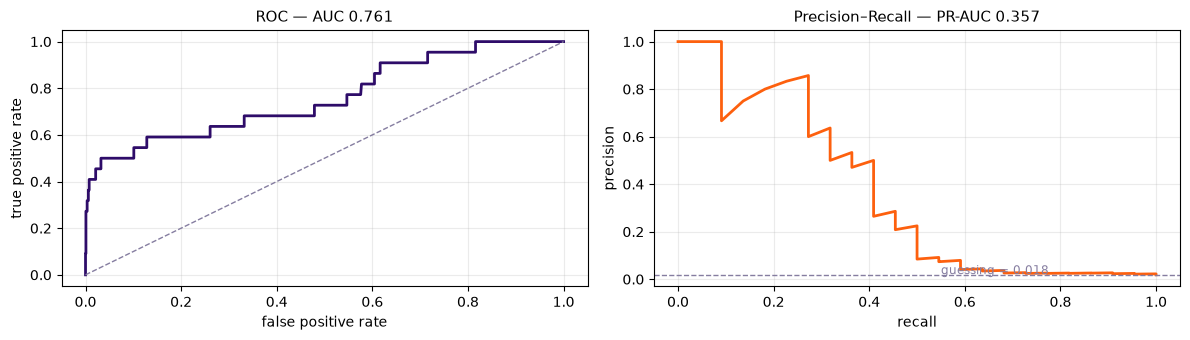

The left curve looks excellent. The right one is the honest picture.

That gap is the whole reason to report both. If you show a client only the ROC
curve for a rare-event problem, you have shown them the flattering half.


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
fpr, tpr, _ = roc_curve(y_te, p_te)
ax1.plot(fpr, tpr, color="#2E0C69", lw=2)
ax1.plot([0,1],[0,1],"--",color="#857DA0",lw=1)
ax1.set_title(f"ROC — AUC {roc:.3f}", fontsize=11)
ax1.set_xlabel("false positive rate"); ax1.set_ylabel("true positive rate")

prec, rec, _ = precision_recall_curve(y_te, p_te)
ax2.plot(rec, prec, color="#FD600E", lw=2)
ax2.axhline(base_rate, ls="--", color="#857DA0", lw=1)
ax2.text(0.55, base_rate*1.15, f"guessing = {base_rate:.3f}", fontsize=8.5, color="#857DA0")
ax2.set_title(f"Precision–Recall — PR-AUC {pr:.3f}", fontsize=11)
ax2.set_xlabel("recall"); ax2.set_ylabel("precision")
plt.tight_layout(); plt.show()

print("""The left curve looks excellent. The right one is the honest picture.

That gap is the whole reason to report both. If you show a client only the ROC
curve for a rare-event problem, you have shown them the flattering half.""")

## Exercise 6 · Turn the threshold into a staffing number

This is the FDE move. The client's real question is never *"what is the AUC?"*.
It is:

> **"If we set the threshold here, how many extra cases go to review each day —
> and how many of those turn out to be nothing?"**

That is a staffing question, and an AUC cannot answer it.

In [9]:
CASES_PER_DAY = 4000 / 30      # Meridian's real volume

print(f"{'threshold':>10}{'precision':>11}{'recall':>9}{'flagged/day':>14}"
      f"{'real/day':>10}{'wasted/day':>12}")
print("-" * 68)
rows = []
for th in (0.03, 0.05, 0.10, 0.20, 0.35, 0.50):
    pred = (p_te >= th).astype(int)
    if pred.sum() == 0:
        continue
    p_ = precision_score(y_te, pred, zero_division=0)
    r_ = recall_score(y_te, pred, zero_division=0)
    flagged_rate = pred.mean()
    per_day = flagged_rate * CASES_PER_DAY
    rows.append((th, p_, r_, per_day, per_day*p_, per_day*(1-p_)))
    print(f"{th:>10.2f}{p_:>11.1%}{r_:>9.1%}{per_day:>14.1f}"
          f"{per_day*p_:>10.1f}{per_day*(1-p_):>12.1f}")

print(f"""
Meridian processes about {CASES_PER_DAY:.0f} claims a day.

THE CONVERSATION TO HAVE

Take this table to the operations manager, not to the CTO. The question is
"how many reviews a day can your team absorb?" — and their answer picks the
threshold. Not you.

If they can handle 15 reviews a day, read across to find the threshold that
produces about 15. If the recall at that threshold is 40%, then 40% is your
detection rate and everybody now knows it in advance.

A queue nobody has time to read is worse than no queue, because it looks like
a control and is not one.
""")

 threshold  precision   recall   flagged/day  real/day  wasted/day
--------------------------------------------------------------------
      0.03      24.4%    45.5%           4.6       1.1         3.4
      0.05      29.0%    40.9%           3.4       1.0         2.4
      0.10      34.6%    40.9%           2.9       1.0         1.9
      0.20      40.9%    40.9%           2.4       1.0         1.4
      0.35      50.0%    31.8%           1.6       0.8         0.8
      0.50      75.0%    27.3%           0.9       0.7         0.2

Meridian processes about 133 claims a day.

THE CONVERSATION TO HAVE

Take this table to the operations manager, not to the CTO. The question is
"how many reviews a day can your team absorb?" — and their answer picks the
threshold. Not you.

If they can handle 15 reviews a day, read across to find the threshold that
produces about 15. If the recall at that threshold is 40%, then 40% is your
detection rate and everybody now knows it in advance.

A queue nobo

In [10]:
# Rules only, model only, both together — the table the client will look at.
rule_score_te = cases.loc[idx_te, "rule_score"].values

MODEL_TH = 0.10
combos = {
  "rules only":       (rule_score_te >= 30).astype(int),
  "model only":       (p_te >= MODEL_TH).astype(int),
  "rules OR model":   ((rule_score_te >= 30) | (p_te >= MODEL_TH)).astype(int),
  "rules AND model":  ((rule_score_te >= 30) & (p_te >= MODEL_TH)).astype(int),
}

print(f"{'setup':<20}{'caught':>12}{'false alarms':>14}{'precision':>11}"
      f"{'recall':>9}{'review/day':>12}")
print("-" * 80)
for name, pred in combos.items():
    tp = int(((pred == 1) & (y_te == 1)).sum())
    fp = int(((pred == 1) & (y_te == 0)).sum())
    p_ = tp / max(tp + fp, 1); r_ = tp / max(int(y_te.sum()), 1)
    per_day = pred.mean() * CASES_PER_DAY
    print(f"{name:<20}{f'{tp} of {int(y_te.sum())}':>12}{fp:>14}{p_:>11.1%}"
          f"{r_:>9.1%}{per_day:>12.1f}")

print("""
REPORT ALL FOUR, ALWAYS

A client shown only the combined number cannot tell whether the model earned
its place. Show what the rules alone achieved first.

And say the uncomfortable part out loud: whatever your best row catches, the
rest got through. A client shown "we catch 68%" will hear "we are covered"
unless you tell them plainly that roughly a third still reaches payment.
""")

setup                     caught  false alarms  precision   recall  review/day
--------------------------------------------------------------------------------
rules only               4 of 22             2      66.7%    18.2%         0.7
model only               9 of 22            17      34.6%    40.9%         2.9
rules OR model          10 of 22            19      34.5%    45.5%         3.2
rules AND model          3 of 22             0     100.0%    13.6%         0.3

REPORT ALL FOUR, ALWAYS

A client shown only the combined number cannot tell whether the model earned
its place. Show what the rules alone achieved first.

And say the uncomfortable part out loud: whatever your best row catches, the
rest got through. A client shown "we catch 68%" will hear "we are covered"
unless you tell them plainly that roughly a third still reaches payment.



---

# Day 28 · Wire it into the pipeline

## What we are doing today, and why

For two days the score has been a number in a report. **Today it starts changing
what happens to a real customer's claim** — and that changes the governance
position entirely.

---

## ⚠️ Exercise 7 · The word we are changing

Your syllabus says the routing is **approve / review / reject**.

Sprint 0 decided that DecisionStream **never states a decision** — a person
decides and the system supports them. *"Reject"* is a decision. So is
*"auto-approve"*.

| Risk band | What the syllabus says | What we will build |
|---|---|---|
| Low | `auto-approve` | `straight_through` — a person still signs off |
| Medium | `case-review queue` | `standard_review` — fine as written |
| High | `reject` | `priority_review` — with reasons attached |

**This is not pedantry.** An automated rejection of an insurance claim based on
a risk score is automated decision-making with a legal or similarly significant
effect on a person. That carries obligations — a right to an explanation, to
human intervention, and to contest.

Building it as a queue avoids all of it, costs almost nothing, and is what your
Sprint 0 ADR already committed to. **The code is identical; only the names and
the downstream behaviour change.**

In [11]:
LOW_MAX, HIGH_MIN = 30, 70
ROUTES = ("straight_through", "standard_review", "priority_review")
FORBIDDEN_ROUTE_NAMES = {"approve", "auto_approve", "reject", "decline", "deny"}

def combined_score(case, model_prob):
    """Rules and model together, on a 0-100 scale."""
    r, fired = apply_rules(case)
    m = float(model_prob) * 100
    return min(100, max(r, 0.6 * r + 0.7 * m)), fired

def route_case(case, model_prob=None, scoring_ok=True):
    """
    Returns a routing decision. NOTHING here approves or rejects anything.
    """
    if not scoring_ok:
        # FAIL TOWARDS THE HUMAN. Never away from them.
        return {"route": "standard_review", "score": None, "scored": False,
                "reasons": ["scoring_unavailable"],
                "note": "routed WITHOUT a score - do not assume it was checked"}
    score, fired = combined_score(case, model_prob or 0.0)
    if score >= HIGH_MIN:      route = "priority_review"
    elif score > LOW_MAX:      route = "standard_review"
    else:                      route = "straight_through"
    return {"route": route, "score": round(score, 1), "scored": True,
            "reasons": fired or ["no_rule_fired"],
            "note": "a person decides. always."}

# Guard: no route may ever be named after a decision.
assert not (set(ROUTES) & FORBIDDEN_ROUTE_NAMES), "a route is named after a decision"
print("route names checked - none of them decides anything\n")

MEDIUM_CASE = dict(days_since_incident=26, estimate_vs_limit_pct=0.94,
                   bank_account_reuse_count=0, policy_age_days=800,
                   garage_claim_share_90d=0.03, application_velocity_30d=0)

demo = [("clean claim", tests[0][1], 0.01),
        ("the Meridian shape", tests[4][1], 0.62),
        ("one rule + some model signal", MEDIUM_CASE, 0.22)]
for label, c, mp in demo:
    r = route_case(c, mp)
    print(f"{label:<22}{r['route']:<20}score={r['score']:<7}{', '.join(r['reasons'])}")

r = route_case(demo[1][1], None, scoring_ok=False)
print(f"{'scoring service DOWN':<22}{r['route']:<20}score={str(r['score']):<7}{r['note']}")

print("""
THE FALLBACK IS THE TEST THAT MATTERS

The dangerous default is two lines and very easy to write by accident:

    try:    score = call_scoring(case)
    except: score = 0            # every case now looks low risk, silently

If you cannot score a case, it goes to REVIEW - not straight through. That
costs reviewer time during an outage, which is the correct trade. And record
scored=False so nobody later assumes the case was checked and cleared.
""")

route names checked - none of them decides anything

clean claim           straight_through    score=0.7    no_rule_fired
the Meridian shape    priority_review     score=100    late_and_near_limit, repeated_bank_account, garage_concentration
one rule + some model signalstandard_review     score=33.4   late_and_near_limit
scoring service DOWN  standard_review     score=None   routed WITHOUT a score - do not assume it was checked

THE FALLBACK IS THE TEST THAT MATTERS

The dangerous default is two lines and very easy to write by accident:

    try:    score = call_scoring(case)
    except: score = 0            # every case now looks low risk, silently

If you cannot score a case, it goes to REVIEW - not straight through. That
costs reviewer time during an outage, which is the correct trade. And record
scored=False so nobody later assumes the case was checked and cleared.



In [12]:
# Four tests. The fallback one is the important one.
def test_low_risk_goes_straight_through():
    assert route_case(tests[0][1], 0.01)["route"] == "straight_through"

def test_high_risk_goes_to_priority():
    assert route_case(tests[4][1], 0.62)["route"] == "priority_review"

def test_medium_goes_to_standard():
    # one rule fires (30) plus a moderate model probability -> pushed over LOW_MAX
    assert route_case(MEDIUM_CASE, 0.22)["route"] == "standard_review"

def test_boundary_is_exclusive():
    # a score of exactly LOW_MAX stays low. Boundary conditions are where
    # routing bugs live, so pin the behaviour down with a test.
    assert route_case(MEDIUM_CASE, 0.0)["route"] == "straight_through"

def test_scoring_failure_routes_to_a_human():
    r = route_case(tests[0][1], None, scoring_ok=False)
    assert r["route"] != "straight_through", "unscored case was let through"
    assert r["scored"] is False

def test_no_route_is_a_decision():
    for c, mp in [(t[1], 0.5) for t in tests]:
        assert route_case(c, mp)["route"] in ROUTES

for fn in [test_low_risk_goes_straight_through, test_high_risk_goes_to_priority,
           test_medium_goes_to_standard, test_boundary_is_exclusive,
           test_scoring_failure_routes_to_a_human, test_no_route_is_a_decision]:
    try:
        fn(); print(f"  PASS  {fn.__name__}")
    except AssertionError as e:
        print(f"  FAIL  {fn.__name__}: {e}")

# What the whole book looks like at these thresholds
p_all = model.predict_proba(cases[FEATURES].values)[:, 1]
routes = [route_case(c, p_all[i])["route"] for i, (_, c) in enumerate(cases.iterrows())]
cases["route"] = routes
print("\nrouting across all cases:")
vc = cases.route.value_counts()
for r_ in ROUTES:
    n = int(vc.get(r_, 0))
    print(f"  {r_:<20}{n:>6}  ({n/len(cases):>5.1%})   ~{n/len(cases)*CASES_PER_DAY:>5.1f}/day")
print("\nfraud caught in a review queue: "
      f"{cases[(cases.is_fraud==1) & (cases.route!='straight_through')].shape[0]}"
      f" of {int(cases.is_fraud.sum())}")

  PASS  test_low_risk_goes_straight_through
  PASS  test_high_risk_goes_to_priority
  PASS  test_medium_goes_to_standard
  PASS  test_boundary_is_exclusive
  PASS  test_scoring_failure_routes_to_a_human
  PASS  test_no_route_is_a_decision

routing across all cases:
  straight_through      3931  (98.3%)   ~131.0/day
  standard_review         57  ( 1.4%)   ~  1.9/day
  priority_review         12  ( 0.3%)   ~  0.4/day

fraud caught in a review queue: 59 of 72


## Exercise 8 · Handle the failures properly

The `retryable` taxonomy from Sprint 1 Day 17 already tells you what to do here.
**This is a reuse, not a new design.**

In [13]:
SCORING_FAILURES = [
  ("scoring timeout",           504, True,  "retry with backoff, then queue for review"),
  ("service at capacity",       429, True,  "retry honouring Retry-After"),
  ("variable lookup down",      504, True,  "score with what you have, mark partial"),
  ("malformed event rejected",  400, False, "do not retry - flag as a defect"),
  ("model version not found",   500, False, "fail loudly - this is a deployment fault"),
]
print(f"{'what went wrong':<28}{'code':>6}{'retry?':>9}   what to do")
print("-" * 92)
for name, code_, retryable, action in SCORING_FAILURES:
    print(f"{name:<28}{code_:>6}{str(retryable):>9}   {action}")

print("""
THE RULE: fail towards the human, never away from them.

Every row above ends with the case reaching a person or an engineer. None of
them ends with the case quietly proceeding as though it had been checked.
""")

what went wrong               code   retry?   what to do
--------------------------------------------------------------------------------------------
scoring timeout                504     True   retry with backoff, then queue for review
service at capacity            429     True   retry honouring Retry-After
variable lookup down           504     True   score with what you have, mark partial
malformed event rejected       400    False   do not retry - flag as a defect
model version not found        500    False   fail loudly - this is a deployment fault

THE RULE: fail towards the human, never away from them.

Every row above ends with the case reaching a person or an engineer. None of
them ends with the case quietly proceeding as though it had been checked.



---

# Exercise 9 · Register the model in Azure Machine Learning

Everything above ran locally. This section connects it to a **real Azure ML
workspace** — which is what your syllabus names.

**It is optional.** If you do not have a workspace, skip it; nothing else in the
notebook depends on it. **Appendix A** walks you through creating one.

### What you will need

| Value | Where it comes from |
|---|---|
| Subscription ID | Portal → Subscriptions |
| Resource group | The one holding your workspace |
| Workspace name | The Azure ML workspace you created |

### Signing in from Colab

Colab has no browser session, so `DefaultAzureCredential` will not work on its
own. Use **device code** sign-in: the cell prints a code, you open a link on
your phone or laptop, paste the code, and the notebook is authorised.

In [14]:
SUBSCRIPTION_ID = os.environ.get("AZ_SUB", "").strip()
RESOURCE_GROUP  = os.environ.get("AZ_RG", "").strip()
WORKSPACE_NAME  = os.environ.get("AZ_WS", "").strip()

if not SUBSCRIPTION_ID:
    SUBSCRIPTION_ID = input("Subscription ID (blank to skip Azure): ").strip()
if SUBSCRIPTION_ID:
    if not RESOURCE_GROUP: RESOURCE_GROUP = input("Resource group: ").strip()
    if not WORKSPACE_NAME: WORKSPACE_NAME = input("Azure ML workspace name: ").strip()

AZURE = bool(SUBSCRIPTION_ID and RESOURCE_GROUP and WORKSPACE_NAME)
ml_client = None

if AZURE:
    from azure.identity import DeviceCodeCredential
    from azure.ai.ml import MLClient
    print("A sign-in code will appear below. Open the link, enter the code,")
    print("and come back here.\n")
    cred = DeviceCodeCredential()
    try:
        ml_client = MLClient(cred, SUBSCRIPTION_ID, RESOURCE_GROUP, WORKSPACE_NAME)
        ws = ml_client.workspaces.get(WORKSPACE_NAME)
        print(f"\nconnected to workspace: {ws.name}  ({ws.location})")
    except Exception as e:
        print(f"\ncould not connect: {type(e).__name__}: {str(e)[:160]}")
        print("Check Appendix B for the common causes.")
        AZURE = False
else:
    print("skipping Azure - everything above still stands")

skipping Azure - everything above still stands


In [15]:
import joblib, tempfile, pathlib

MODEL_DIR = pathlib.Path("meridian_model"); MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(model, MODEL_DIR / "model.pkl")

# The model card. This matters more than the .pkl file.
model_card = {
  "name": "meridian_claim_anomaly",
  "purpose": "Rank motor claims by anomaly risk to prioritise HUMAN review",
  "not_for": "Automated approval or rejection of any claim. A person decides.",
  "features": FEATURES,
  "training": {"total_cases": int(len(y_tr) + len(y_te)),
               "fraud_rate": float(cases.is_fraud.mean()),
               "train_size": int(len(y_tr)), "test_size": int(len(y_te)),
               "fraud_in_test": int(y_te.sum())},
  "metrics": {"roc_auc": round(float(roc), 3),
              "pr_auc": round(float(pr), 3),
              "baseline_pr": round(float(base_rate), 4)},
  "thresholds": {"low_max": LOW_MAX, "high_min": HIGH_MIN,
                 "chosen_by": "TODO - name the operations manager who agreed these"},
  "known_limitations": [
    "SELECTION BIAS: labels come only from fraud that was DETECTED. Fraud never "
    "found is invisible to this model, by construction, and more data of the "
    "same kind will not fix it.",
    f"Only {int(y_te.sum())} fraud cases in the test set - metrics are noisy.",
    "Trained on synthetic data. Re-measure on real claims before production.",
    "garage_claim_share_90d may act as a proxy for community in a small town. "
    "Review per geography.",
  ],
  "reviewed_by": "TODO - name and date",
}
(MODEL_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2))
print(json.dumps(model_card, indent=2)[:1200])

{
  "name": "meridian_claim_anomaly",
  "purpose": "Rank motor claims by anomaly risk to prioritise HUMAN review",
  "not_for": "Automated approval or rejection of any claim. A person decides.",
  "features": [
    "declared_income",
    "estimate_vs_limit_pct",
    "days_since_incident",
    "application_velocity_30d",
    "device_fingerprint_reuse",
    "bank_account_reuse_count",
    "garage_claim_share_90d",
    "policy_age_days"
  ],
  "training": {
    "total_cases": 4000,
    "fraud_rate": 0.018,
    "train_size": 2800,
    "test_size": 1200,
    "fraud_in_test": 22
  },
  "metrics": {
    "roc_auc": 0.761,
    "pr_auc": 0.357,
    "baseline_pr": 0.0183
  },
  "thresholds": {
    "low_max": 30,
    "high_min": 70,
    "chosen_by": "TODO - name the operations manager who agreed these"
  },
  "known_limitations": [
    "SELECTION BIAS: labels come only from fraud that was DETECTED. Fraud never found is invisible to this model, by construction, and more data of the same kind will n

In [16]:
if AZURE and ml_client is not None:
    from azure.ai.ml.entities import Model
    from azure.ai.ml.constants import AssetTypes
    try:
        registered = ml_client.models.create_or_update(Model(
            path=str(MODEL_DIR),
            type=AssetTypes.CUSTOM_MODEL,
            name="meridian-claim-anomaly",
            description="Ranks motor claims for HUMAN review. Never decides.",
            tags={"roc_auc": f"{roc:.3f}", "pr_auc": f"{pr:.3f}",
                  "fraud_rate": f"{cases.is_fraud.mean():.4f}",
                  "decides_outcomes": "no", "sprint": "2"},
        ))
        print(f"registered: {registered.name}  version {registered.version}")
        print("\nOpen ml.azure.com -> Models to see it, with the tags attached.")
        print("The tag decides_outcomes=no is deliberate: it is a machine-readable")
        print("statement of what this model is NOT allowed to do.")
    except Exception as e:
        print(f"registration failed: {type(e).__name__}: {str(e)[:200]}")
else:
    print("no workspace connected - the model card is still on disk and is")
    print("the artefact that actually matters for the ADR")

no workspace connected - the model card is still on disk and is
the artefact that actually matters for the ADR


---

# Appendix A · Creating the Azure ML workspace, step by step

Twenty minutes. Free tier is fine for this exercise — you will not train on
Azure compute, only register a model.

## Step 1 · Sign in

Go to **https://portal.azure.com** and sign in with the account that has your
subscription.

## Step 2 · Create a resource group

A resource group is a folder. Putting everything in one makes cleanup a single
delete.

1. Search for **Resource groups** → **Create**
2. Choose your subscription
3. Name it `rg-forge-sprint2`
4. Choose a region — note it down
5. **Review + create** → **Create**

## Step 3 · Create the Azure Machine Learning workspace

1. In the top search bar, type **Azure Machine Learning**
2. Select **Azure Machine Learning** → **Create** → **New workspace**
3. Fill in:

| Field | Value | Note |
|---|---|---|
| Subscription | yours | |
| Resource group | `rg-forge-sprint2` | the one you just made |
| Workspace name | `mlw-forge-sprint2` | must be unique in the region |
| Region | same as the resource group | keep them together |
| Storage / Key vault / App Insights | leave as **Create new** | Azure makes them for you |

4. **Review + create** → **Create**
5. Deployment takes **3–5 minutes** — longer than most resources, because it is
   creating four things

> **Note:** the workspace automatically creates a storage account, a key vault
> and an Application Insights resource. That is normal. They are all inside your
> resource group, so deleting the group removes everything.

## Step 4 · Collect the three values the notebook needs

1. Open your workspace in the portal
2. On the **Overview** page you will see:
   - **Subscription ID** — a long GUID
   - **Resource group** — `rg-forge-sprint2`
   - **Name** — `mlw-forge-sprint2`
3. Copy all three

> **There is no key to copy.** Azure ML uses your Azure identity, not an API
> key. That is why the notebook uses device-code sign-in instead of asking for
> a secret — and it is a better security posture than a key you paste around.

## Step 5 · Give yourself permission (if it fails later)

If registration fails with an authorisation error:

1. Open the workspace → **Access control (IAM)**
2. **Add** → **Add role assignment**
3. Role: **AzureML Data Scientist** (or **Contributor**)
4. Assign to your own user account
5. Save, wait two minutes for it to propagate

## Step 6 · Clean up when you are finished

1. Search **Resource groups** → open `rg-forge-sprint2`
2. **Delete resource group**, type the name to confirm

That removes the workspace, storage, key vault and App Insights together.

---

# Appendix B · When it does not work

| What you see | What it usually means | What to do |
|---|---|---|
| `DefaultAzureCredential failed` | Colab has no browser session | Use `DeviceCodeCredential`, as this notebook does |
| Device code prompt never appears | The cell is still installing | Wait for the `%pip` cell to finish first |
| `AuthorizationFailed` | Your account has no role on the workspace | Appendix A, Step 5 |
| `ResourceNotFound` on the workspace | Name, resource group or subscription is wrong | Re-copy all three from the Overview page |
| `SubscriptionNotFound` | Signed in with a different tenant | Sign out of the device-code session and retry |
| Workspace creation greyed out | Region has no capacity or quota | Pick a different region |
| Registration hangs | Uploading the model folder | It is a few hundred KB; if it hangs over two minutes, check the storage account exists |

---

# Questions for the ADR

1. **Who approved the variable list, and when?** In two years somebody will ask
   why `garage_claim_share_90d` is in there.
2. **Which variables need a live lookup**, and does that lookup exist and stay
   current? Three of the eight do.
3. **What is your PR-AUC**, not just your ROC AUC? With a rare positive class
   they tell different stories.
4. **How many reviews per day does your threshold produce**, and who agreed to
   staff them? A queue nobody reads is not a control.
5. **What proportion of fraud still gets through?** Say the number out loud
   before a client infers coverage you have not promised.
6. **Is any route in your code named `approve` or `reject`?** If so, rename it
   today. It is cheaper now than after a regulator asks.
7. **What happens when scoring is unavailable?** If the answer is "the case
   proceeds", you have built a silent failure.

---

### The sentence to carry out of these three days

> **A score is not a verdict. It is a queue.**
>
> Everything you built decides how quickly a person looks at a case — and
> nothing more than that.